# Cy comparison

Compare one balanced primary-only baseline with synchronized transport at
$C_y=0.1$, $0.5$ and $0.7$. Every run uses the same committed AnnData, frozen map,
training settings and initial network weights, so only the secondary-space weight changes.

In [1]:
from pathlib import Path
import sys
import uuid

example_dir = next(parent / "examples" for parent in (Path.cwd(), *Path.cwd().parents)
                   if (parent / "examples" / "synthetic_gaussian_assets.py").is_file())
if str(example_dir) not in sys.path:
    sys.path.insert(0, str(example_dir))

import anndata as ad
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import coati as ct
from gaussian_map import evaluate_bump_map
from gaussian_comparison import (
    make_shared_initial_checkpoint,
    plot_gaussian_sync,
    plot_bump_height,
    compare_gaussian_runs,
)
from synthetic_gaussian_assets import load_shared_gaussian_assets, resolve_asset_directory

%matplotlib inline
torch.set_num_threads(1)
plt.rcParams.update({"font.family": "Arial", "font.size": 11})
run_dir = Path("outputs") / ("gaussian-cy-" + uuid.uuid4().hex[:8])
run_dir.mkdir(parents=True)
print("Result directory:", run_dir)

Result directory: outputs/gaussian-cy-b16fd8fc


## Shared data and frozen map

The observations contain 1,000 initial cells and two terminal components of 1,000 cells.
The larger terminal sample does not change mass in this balanced comparison.

In [2]:
asset_dir = resolve_asset_directory()
cells, T, map_payload = load_shared_gaussian_assets(directory=asset_dir)
map_pairs = ad.read_h5ad(asset_dir / "map_pairs.h5ad")
data = ct.TemporalData.from_anndata(
    cells, obsm_key="X_latent", secondary_obsm_key="X_secondary"
)
map_scores, map_grid = evaluate_bump_map(T, map_pairs, grid_n=96)
assert [len(snapshot) for snapshot in data.primary] == [1000, 2000]
assert not any(parameter.requires_grad for parameter in T.parameters())
display(map_scores.round(6))
print(f"Grid z correlation: {map_grid['z_correlation']:.6f}")

,Pairs,XY_RMSE,Z_RMSE,Z_MAE
Evaluation,,,,
Held-out observed,434,0.000047,0.021079,0.004067
Held-out support,1066,0.000065,0.005544,0.003500
Independent grid,9216,0.000067,0.005036,0.002998


Grid z correlation: 0.999378


## Configure the Cy sweep

The no-sync baseline has $C_y=0$. The three synchronized runs differ only in
`secondary_weight`, the public name for $C_y$. All four models are balanced.

In [3]:
base_config = ct.Config(
    multimodal=True,
    balanced=True,
    iterations=3000,
    batch_size=256,
    hidden_dim=256,
    secondary_weight=.5,
    extra={"median_n_sample": 512, "floor_n_sample": 256, "adaptive_lambda": True},
)
configs = {"No sync": base_config.with_parameters(multimodal=False, secondary_weight=0.)}
for cy in [.1, .5, .7]:
    configs[f"Cy={cy:g}"] = base_config.with_parameters(secondary_weight=cy)

pd.DataFrame({name: {key: cfg.to_dict()[key] for key in
    ["niters", "num_samples", "sync_loss", "sync_weight", "unbalancedModel"]}
    for name, cfg in configs.items()})

,No sync,Cy=0.1,Cy=0.5,Cy=0.7
niters,3000,3000,3000,3000
num_samples,256,256,256,256
sync_loss,False,True,True,True
sync_weight,0.0,0.1,0.5,0.7
unbalancedModel,False,False,False,False


## Train once in balanced mode

All four runs start from one shared weight-only checkpoint. There is no warm-up and no
unbalanced growth field.

In [4]:
initial = make_shared_initial_checkpoint(base_config, run_dir / "initial.pt")
results = {}
for name, cfg in configs.items():
    print("Training:", name, flush=True)
    slug = name.lower().replace("=", "").replace(".", "p").replace(" ", "-")
    results[name] = ct.train_vector_field(
        cells, cfg, use_rep="X_latent", secondary_obsm_key="X_secondary",
        T_model=T if cfg.multimodal else None,
        output_dir=run_dir / slug,
        warm_start_path=initial,
    )

Training: No sync


Training: Cy=0.1


Training: Cy=0.5


Training: Cy=0.7


## Trajectories across Cy

Increasing $C_y$ places progressively more weight on the secondary-space kinetic action.
All initial particles are shown without trajectory selection or smoothing.

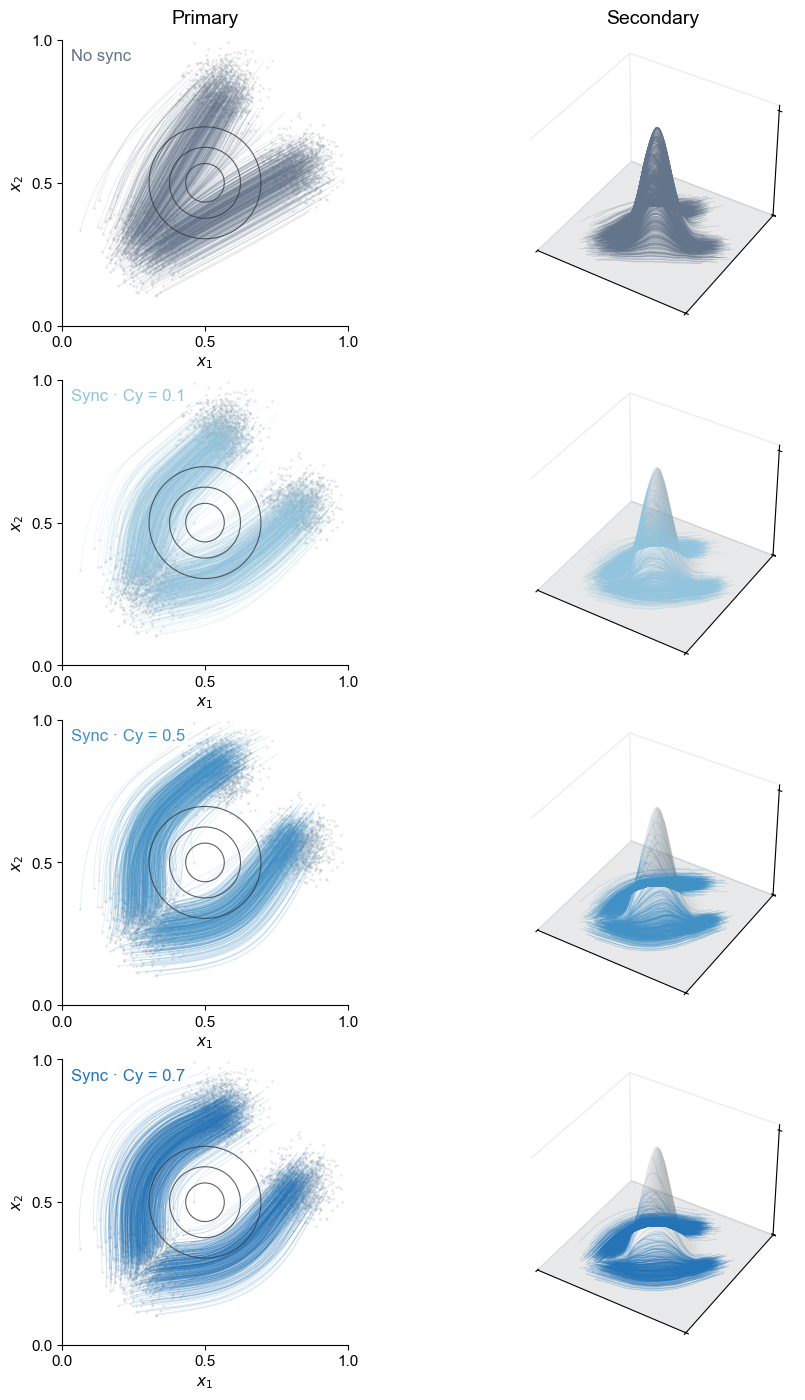

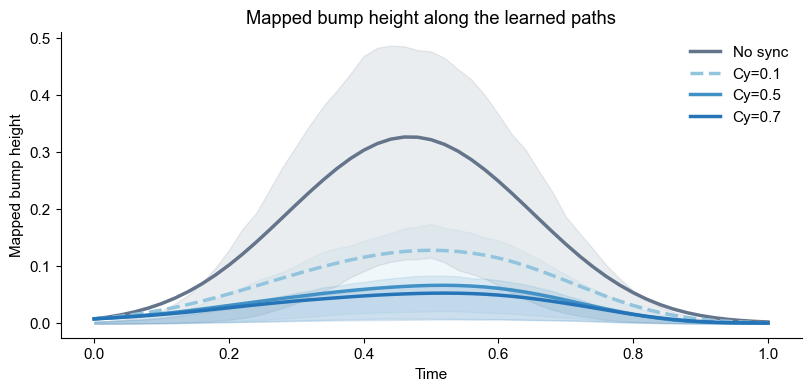

In [5]:
predictions = {}
for name, result in results.items():
    prediction = result.predict_trajectory(times=np.linspace(0., 1., 51), method="rk4")
    with torch.no_grad():
        prediction["secondary"] = T(
            torch.as_tensor(prediction["primary"], dtype=torch.float32)
        ).numpy()
    predictions[name] = prediction

plot_gaussian_sync(data, T, results, predictions)
plt.show()
plot_bump_height(predictions)
plt.show()

## Diagnostics

In [6]:
scores = compare_gaussian_runs(results, predictions)
scores.T.round(6)

Model,No sync,Cy=0.1,Cy=0.5,Cy=0.7
Primary endpoint Sinkhorn,0.000206,0.000120,0.001425,0.000807
Primary kinetic energy,0.161313,0.180034,0.213448,0.204413
Secondary kinetic energy,0.999115,0.374621,0.266299,0.232102
Predicted terminal mass,1.000000,1.000000,1.000000,1.000000
Target terminal mass,1.000000,1.000000,1.000000,1.000000
Median maximum bump height,0.380628,0.093191,0.038393,0.029090
States outside unit square,0.000000,0.000000,0.000000,0.000000


Under the shared 3,000-step budget, the median maximum mapped bump height decreases from 0.380628 without synchronization to 0.093191, 0.038393 and 0.029090 at $C_y=0.1$, $0.5$ and $0.7$, respectively. All four runs retain unit terminal mass.